## Open Tools, Open Sky
### Doing LSST Science with Public Rubin Data & LINCC Frameworks
#### Latest update: Jorge I. Zuluaga

## Reading and understanding VRO observations submitted to MPC

Data source is: https://b612.ai/rubin-mpc-downloads/

In [68]:
from util import *
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display
import matplotlib.pyplot as plt
!mkdir -p data figures

fig_dir='figures/'
data_dir='data/'
%load_ext autoreload 
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Data file and schema:

In [69]:
data_file = data_dir + 'obs_sbn_X05_full.parquet'
columns = pq.read_schema(data_file).names
print_list(columns)

id, trksub, trkid, obsid, submission_id, submission_block_id, obs80, status,
ref, healpix, permid, provid, artsat, mode, stn, trx, rcv, sys, ctr, pos1, pos2,
pos3, poscov11, poscov12, poscov13, poscov22, poscov23, poscov33, prog, obstime,
ra, dec, rastar, decstar, obscenter, deltara, deltadec, dist, pa, rmsra, rmsdec,
rmsdist, rmspa, rmscorr, delay, rmsdelay, doppler, rmsdoppler, astcat, mag,
rmsmag, band, photcat, photap, nucmag, logsnr, seeing, exp, rmsfit, com, frq,
disc, subfrm, subfmt, prectime, precra, precdec, unctime, notes, remarks,
deprecated, localuse, nstars, prev_desig, prev_ref, rmstime, created_at,
updated_at, trkmpc, orbit_id, designation_asterisk, shapeocc, obssubid,
replacesobsid, group_id, vel1, fltr, vel3, vel2, obstime_text


Importing parquet since it is binary and reading is faster:

In [11]:
df_sel = pd.read_parquet(
    data_file,
    columns=['obsid', 'ra', 'dec', 'mag'],
    # filters=[('band', '==', 'r')]
)
df_sel.info(), df_sel.memory_usage(deep=True).sum()/1024**2

<class 'pandas.DataFrame'>
RangeIndex: 8078546 entries, 0 to 8078545
Data columns (total 4 columns):
 #   Column  Dtype
---  ------  -----
 0   obsid   str  
 1   ra      str  
 2   dec     str  
 3   mag     str  
dtypes: str(4)
memory usage: 647.6 MB


(None, np.float64(647.5586929321289))

Convert to numeric:

In [22]:
df_sel[['ra', 'dec', 'mag']] = df_sel[['ra', 'dec', 'mag']].apply(pd.to_numeric, errors='coerce')

### Observations location

Load ecliptic and galactic equator points:

In [61]:
ecl_coords, gal_coords = ecl_gal()

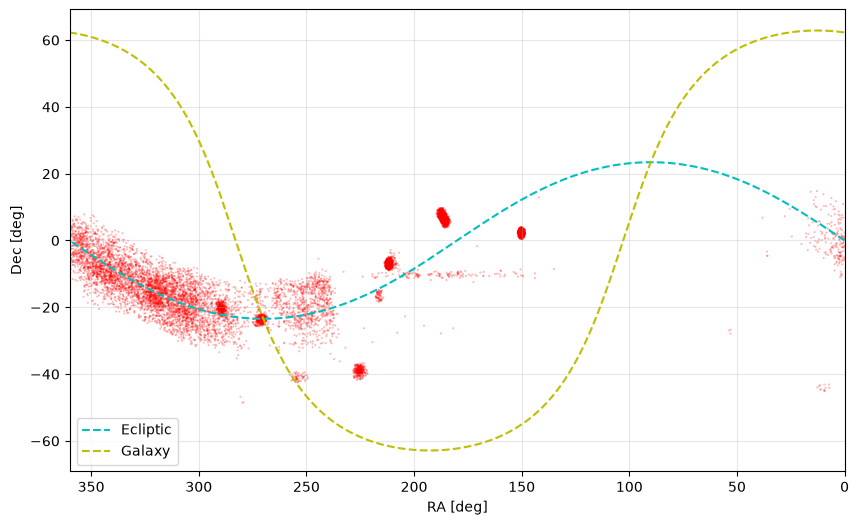

In [74]:
sample = df_sel.sample(10000)
fig, ax = plt.subplots(1,1,figsize=(10, 6))
ax.scatter(sample['ra'], sample['dec'], s=sample['mag']*0.01, alpha=0.3, c='r')

ax.plot(ecl_coords[0], ecl_coords[1],'c--',label='Ecliptic')
ax.plot(gal_coords[0], gal_coords[1],'y--',label='Galaxy')
ax.legend()

ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.set_xlim(360,0)
ax.grid(alpha=0.3)
fig.savefig(fig_dir + 'scatter-observations.png')
#ax.invert_xaxis()

Density of observations:

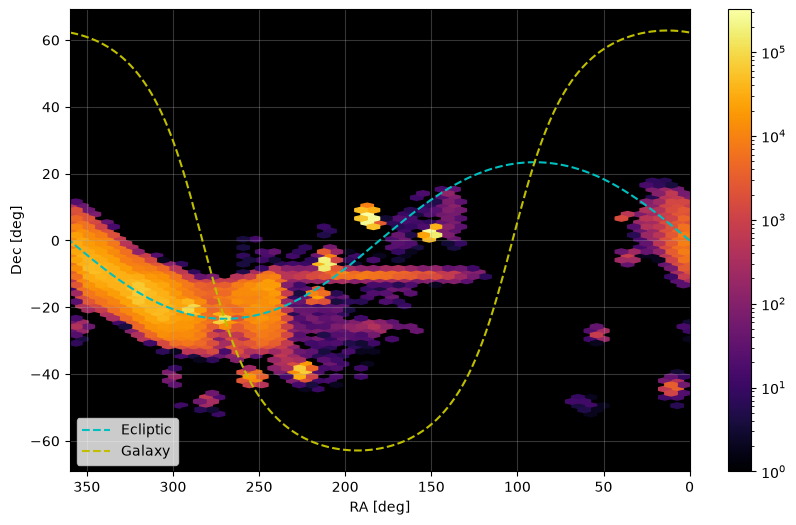

In [73]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.set_facecolor('k')
hb = ax.hexbin(df_sel['ra'], df_sel['dec'], gridsize=50, bins='log', cmap='inferno')
fig.colorbar(hb)

ax.plot(ecl_coords[0], ecl_coords[1],'c--',label='Ecliptic')
ax.plot(gal_coords[0], gal_coords[1],'y--',label='Galaxy')
ax.legend()

ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.set_xlim(360,0)
ax.grid(alpha=0.3)
fig.savefig(fig_dir + 'hexbin-observations.png')